In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [37]:
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "pavansubhasht/ibm-hr-analytics-attrition-dataset","WA_Fn-UseC_-HR-Employee-Attrition.csv"
)
print("Dataset Shape:", df.shape)
df.head()

/tmp/ipython-input-1251707808.py:1: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [38]:
df = df.drop(['Over18','EmployeeCount', 'EmployeeNumber', 'StandardHours'], axis=1)

In [39]:
le = LabelEncoder()
df['Attrition'] = le.fit_transform(df['Attrition'])
df['Attrition']

,Attrition
0,1
1,0
2,1
3,0
4,0
...,...
1465,0
1466,0
1467,0
1468,0


In [40]:
categorical_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender',
                    'JobRole', 'MaritalStatus', 'OverTime']
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

In [41]:
X = df.drop('Attrition', axis=1)
y = df['Attrition']

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [43]:
base_tree = DecisionTreeClassifier(max_depth=8, random_state=42)

In [44]:
bag_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=50,
    random_state=42,
    bootstrap=True
)

In [46]:
bag_model.fit(X_train, y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8,
                                                   random_state=42),
                  n_estimators=50, random_state=42)

In [47]:
y_pred = bag_model.predict(X_test)
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.8469387755102041

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.97      0.91       247
           1       0.56      0.19      0.29        47

    accuracy                           0.85       294
   macro avg       0.71      0.58      0.60       294
weighted avg       0.82      0.85      0.81       294



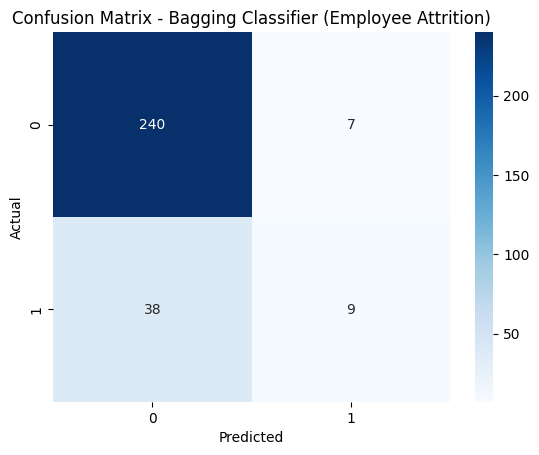

In [48]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Bagging Classifier (Employee Attrition)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

/tmp/ipython-input-543946763.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=importances.index, palette="coolwarm")


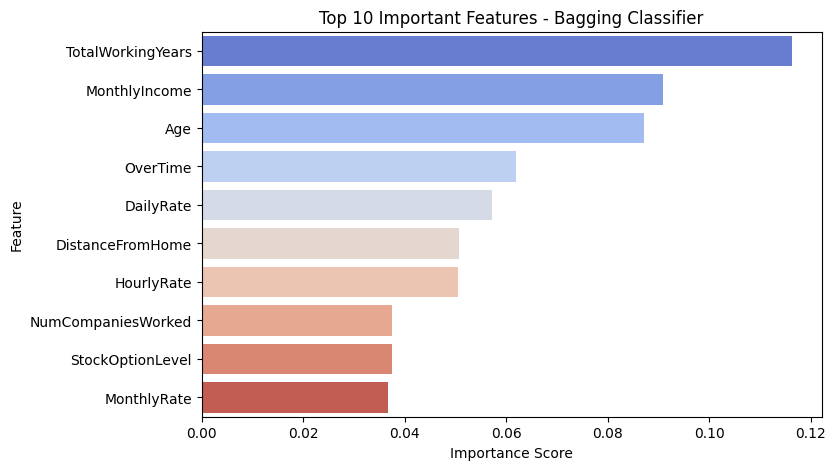

In [49]:
import numpy as np
importances = np.mean([tree.feature_importances_ for tree in bag_model.estimators_], axis=0)
importances = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=importances, y=importances.index, palette="coolwarm")
plt.title("Top 10 Important Features - Bagging Classifier")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

In [51]:
sample_employee = {
    'Age': 35,
    'BusinessTravel': 1,
    'DailyRate': 1100,
    'Department': 2,
    'DistanceFromHome': 10,
    'Education': 3,
    'EducationField': 2,
    'EnvironmentSatisfaction': 2,
    'Gender': 1,
    'HourlyRate': 65,
    'JobInvolvement': 3,
    'JobLevel': 2,
    'JobRole': 4,
    'JobSatisfaction': 2,
    'MaritalStatus': 0,
    'MonthlyIncome': 6500,
    'MonthlyRate': 20000,
    'NumCompaniesWorked': 2,
    'OverTime': 1,
    'PercentSalaryHike': 15,
    'PerformanceRating': 3,
    'RelationshipSatisfaction': 2,
    'StockOptionLevel': 0,
    'TotalWorkingYears': 10,
    'TrainingTimesLastYear': 3,
    'WorkLifeBalance': 3,
    'YearsAtCompany': 5,
    'YearsInCurrentRole': 3,
    'YearsSinceLastPromotion': 1,
    'YearsWithCurrManager': 3
}


sample_df = pd.DataFrame([sample_employee])
prediction = bag_model.predict(sample_df)
prediction_proba = bag_model.predict_proba(sample_df)

if prediction[0] == 1:
    print("\nPrediction: Employee is likely to LEAVE.")
else:
    print("\nPrediction: Employee is likely to STAY.")

print("Prediction Probabilities (Stay / Leave):", prediction_proba[0])


Prediction: Employee is likely to STAY.
Prediction Probabilities (Stay / Leave): [0.83522097 0.16477903]
